# Análisis EDA — Fuga de clientes (Churn)
Universidad del Pacífico

La numeración de las secciones corresponde a los apartados del enunciado.

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


## 0. Preparación del entorno

In [ ]:
!pip install ydata-profiling missingno -q

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 400.8/400.8 kB 20.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 296.7/296.7 kB 18.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.1/3.1 MB 77.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 682.5/682.5 kB 32.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 105.4/105.4 kB 6.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 72.0/72.0 kB 4.0 MB/s eta 0:00:00


In [ ]:
import numpy as np                  # álgebra lineal
import pandas as pd                 # manejo de datos
import seaborn as sns               # gráficos
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick   # formato de ejes
import missingno as msno            # visualización de nulos
import math

from collections import Counter
from ydata_profiling import ProfileReport

sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 110
pd.set_option("display.max_columns", 50)

/tmp/ipykernel_4132/1384970484.py:10: DeprecationWarning: 
    `import ydata_profiling` is deprecated and will not receive more updates. 
    Please install fg-data-profiling via `pip install fg-data-profiling` and use `import data_profiling` instead.
    
  from ydata_profiling import ProfileReport


## 1. Comprensión de datos

Estructura de la tabla, dimensiones, tipos de variables y variable objetivo.

In [ ]:
RUTA = "/content/Copia de WA_Fn-UseC_-Telco-Customer-Churn (8).csv"

In [ ]:
# RUTA = "/content/WA_Fn-UseC_-Telco-Customer-Churn (7).csv"   # ajustar según dónde esté el archivo

df = pd.read_csv(RUTA)
df.head(3)

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes


In [ ]:
df.tail(3)

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
7040,4801-JZAZL,Female,0,Yes,Yes,11,No,No phone service,DSL,Yes,No,No,No,No,No,Month-to-month,Yes,Electronic check,29.60,346.45,No
7041,8361-LTMKD,Male,1,Yes,No,4,Yes,Yes,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Mailed check,74.40,306.6,Yes
7042,3186-AJIEK,Male,0,No,No,66,Yes,No,Fiber optic,Yes,No,Yes,Yes,Yes,Yes,Two year,Yes,Bank transfer (automatic),105.65,6844.5,No


In [ ]:
df.columns.values

array(['customerID', 'gender', 'SeniorCitizen', 'Partner', 'Dependents',
       'tenure', 'PhoneService', 'MultipleLines', 'InternetService',
       'OnlineSecurity', 'OnlineBackup', 'DeviceProtection',
       'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract',
       'PaperlessBilling', 'PaymentMethod', 'MonthlyCharges',
       'TotalCharges', 'Churn'], dtype=object)

In [ ]:
df.shape

(7043, 21)

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null   object 


In [ ]:
df.dtypes

,0
customerID,object
gender,object
SeniorCitizen,int64
Partner,object
Dependents,object
tenure,int64
PhoneService,object
MultipleLines,object
InternetService,object
OnlineSecurity,object


In [ ]:
# Variable objetivo
df["Churn"].value_counts(normalize=True).round(4) * 100

,proportion
Churn,
No,73.46
Yes,26.54


### 1.1 Perfilado automático

In [ ]:
ProfileReport(df)

Output hidden; open in https://colab.research.google.com to view.

## 2. Limpieza inicial

### 2.1 Conversión de tipos
`TotalCharges` llega como texto y debe convertirse a numérica.

In [ ]:
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")
df.dtypes

,0
customerID,object
gender,object
SeniorCitizen,int64
Partner,object
Dependents,object
tenure,int64
PhoneService,object
MultipleLines,object
InternetService,object
OnlineSecurity,object


### 2.2 Identificación de valores nulos

In [ ]:
df.isnull().sum()

,0
customerID,0
gender,0
SeniorCitizen,0
Partner,0
Dependents,0
tenure,0
PhoneService,0
MultipleLines,0
InternetService,0
OnlineSecurity,0


In [ ]:
# Porcentaje de nulos por columna
(df.isnull().sum() / len(df)) * 100

,0
customerID,0.000000
gender,0.000000
SeniorCitizen,0.000000
Partner,0.000000
Dependents,0.000000
tenure,0.000000
PhoneService,0.000000
MultipleLines,0.000000
InternetService,0.000000
OnlineSecurity,0.000000


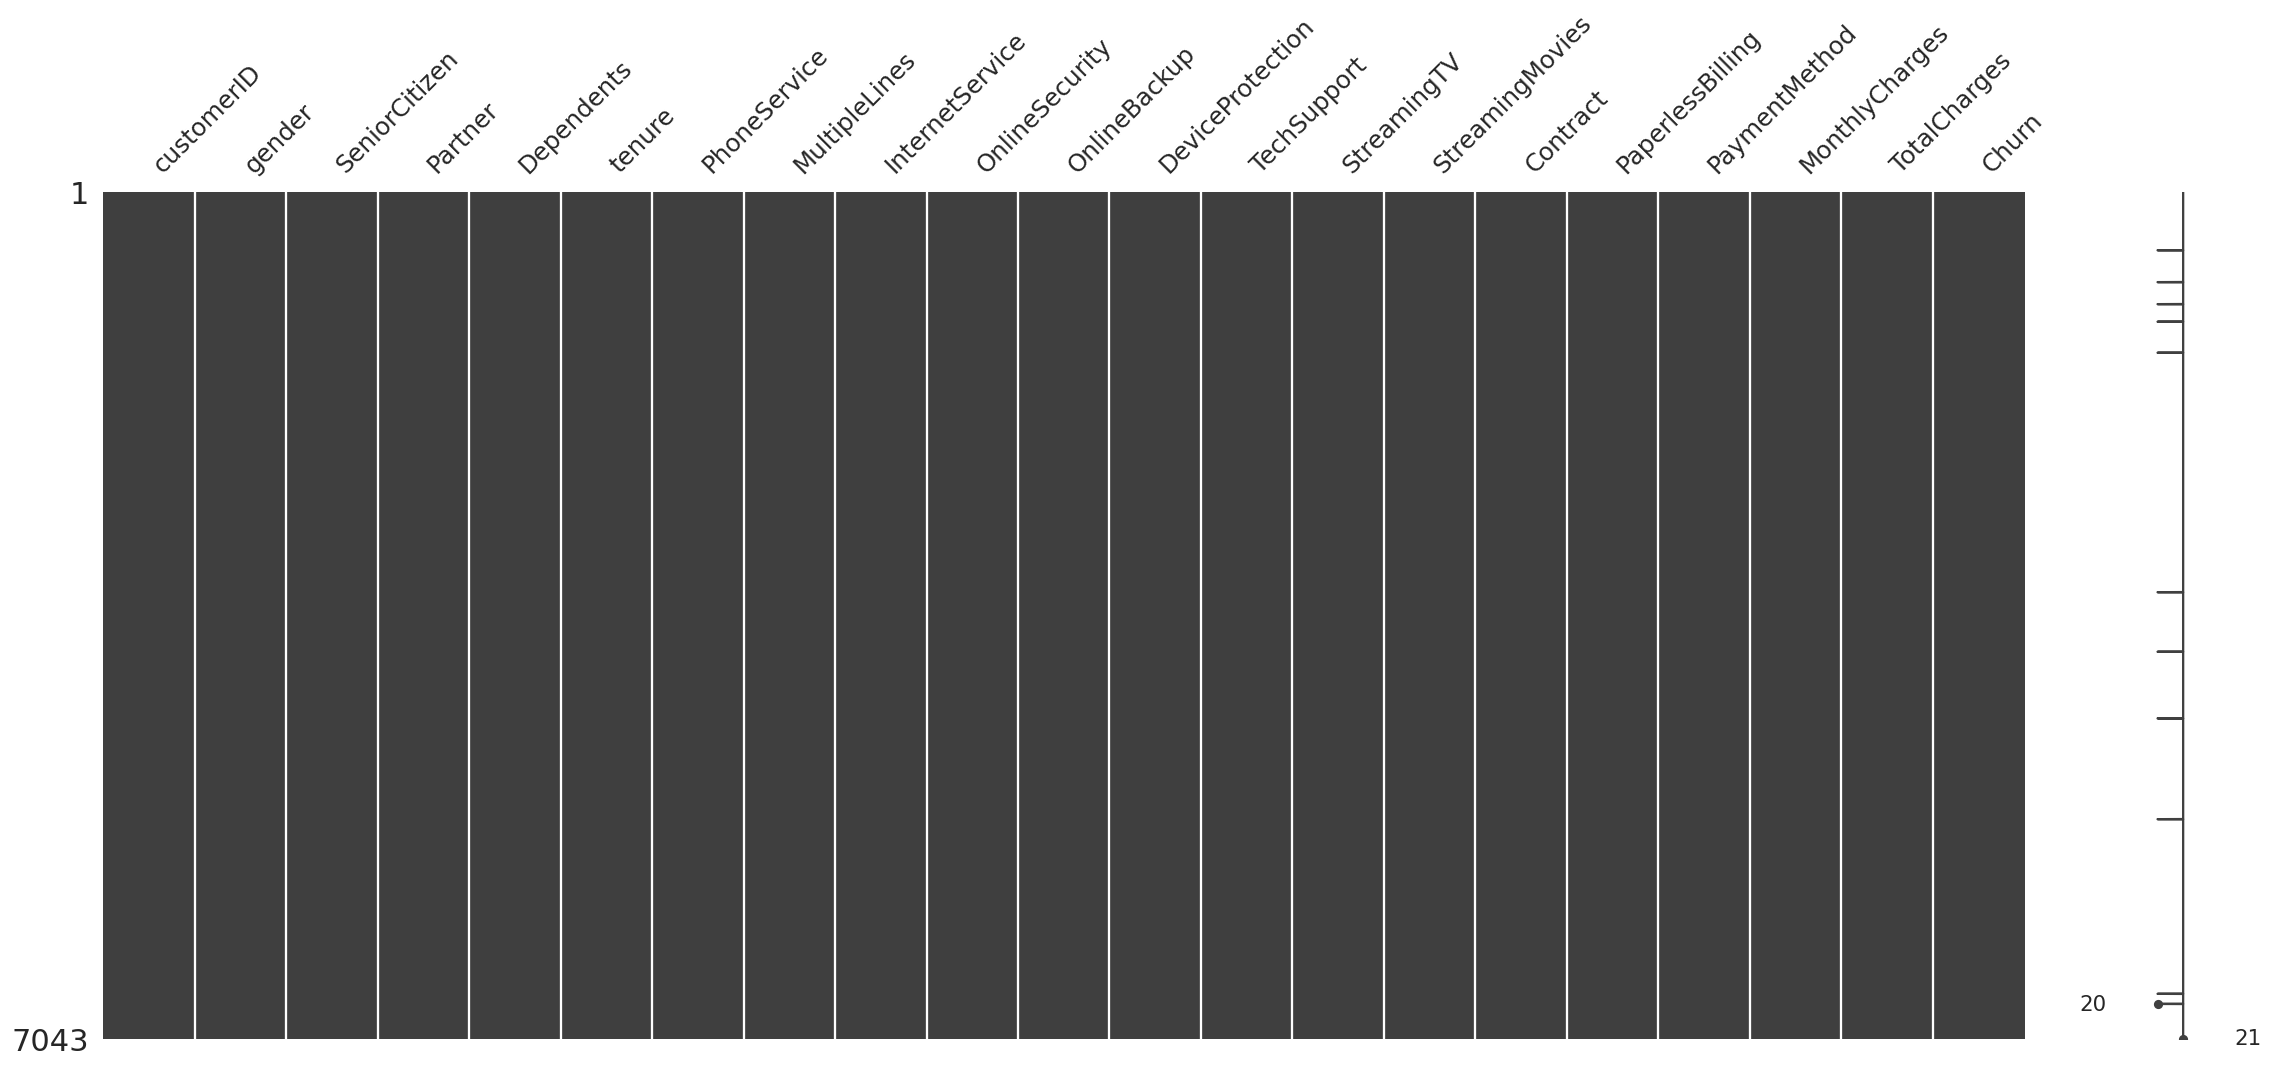

In [ ]:
# Matriz de valores faltantes
msno.matrix(df);

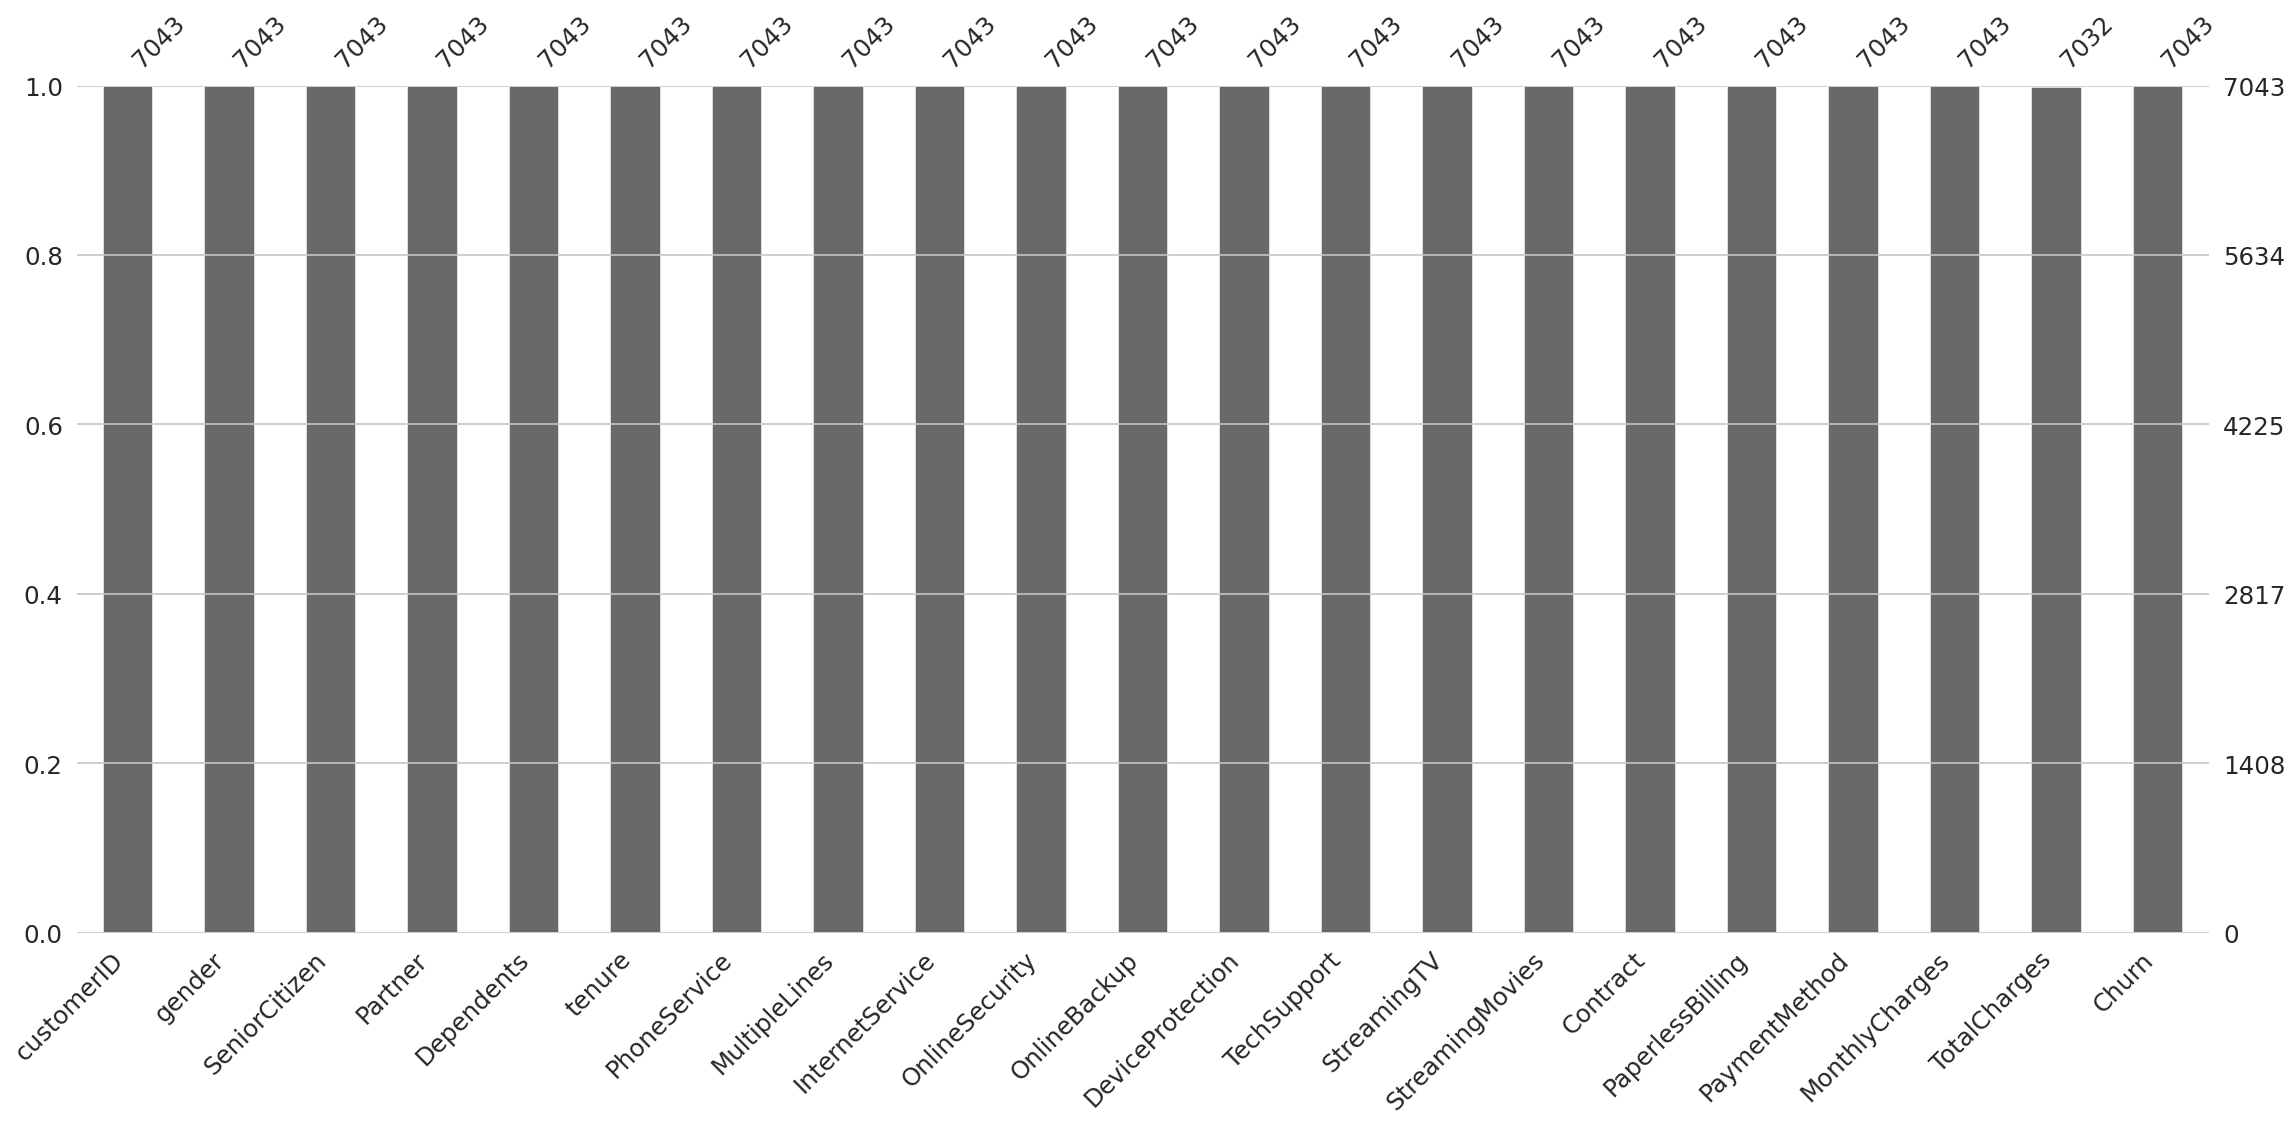

In [ ]:
# Barras de valores faltantes
msno.bar(df=df);

In [ ]:
# ¿Qué tienen en común los registros con TotalCharges nulo?
df.loc[df["TotalCharges"].isnull(), ["customerID", "tenure", "MonthlyCharges", "TotalCharges", "Churn"]]

,customerID,tenure,MonthlyCharges,TotalCharges,Churn
488,4472-LVYGI,0,52.55,NaN,No
753,3115-CZMZD,0,20.25,NaN,No
936,5709-LVOEQ,0,80.85,NaN,No
1082,4367-NUYAO,0,25.75,NaN,No
1340,1371-DWPAZ,0,56.05,NaN,No
3331,7644-OMVMY,0,19.85,NaN,No
3826,3213-VVOLG,0,25.35,NaN,No
4380,2520-SGTTA,0,20.00,NaN,No
5218,2923-ARZLG,0,19.70,NaN,No
6670,4075-WKNIU,0,73.35,NaN,No


### 2.3 Tratamiento y preparación

In [ ]:
# Eliminación de los valores faltantes
dfc

# Se retira el ID del cliente para el análisis
df2 = df.iloc[:, 1:]

# Variable objetivo a binaria
df2["Churn"] = df2["Churn"].map({"Yes": 1, "No": 0})

df2.head()

,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,0
1,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.50,0
2,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,1
3,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,0
4,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,1


In [ ]:
(df2.isnull().sum() / len(df2)) * 100

,0
gender,0.0
SeniorCitizen,0.0
Partner,0.0
Dependents,0.0
tenure,0.0
PhoneService,0.0
MultipleLines,0.0
InternetService,0.0
OnlineSecurity,0.0
OnlineBackup,0.0


### 2.4 Análisis de valores duplicados

In [ ]:
# ¿Son clientes repetidos o clientes distintos con el mismo perfil?
print("Duplicados con customerID: ", df.duplicated().sum())
print("customerID únicos:         ", df["customerID"].nunique(), "de", len(df))
print("Duplicados sin customerID: ", df2.duplicated().sum())

Duplicados con customerID:  0
customerID únicos:          7032 de 7032
Duplicados sin customerID:  22


In [ ]:
df2.drop_duplicates(inplace=True)
df2.shape

(7010, 20)

## 3. Exploración de variables categóricas

In [ ]:
df2.columns

Index(['gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure',
       'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity',
       'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV',
       'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod',
       'MonthlyCharges', 'TotalCharges', 'Churn'],
      dtype='object')

In [ ]:
columnsString = ['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines',
                 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection',
                 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract',
                 'PaperlessBilling', 'PaymentMethod', 'Churn']

In [ ]:
for x in columnsString:
    frecuencias = df2[x].value_counts(dropna=False)
    porcentajes = (frecuencias / len(df2)) * 100
    print(x)
    print(pd.DataFrame({"Frecuencia": frecuencias, "Porcentaje (%)": porcentajes}).round(2))
    print("\n")

gender
        Frecuencia  Porcentaje (%)
gender                            
Male          3535           50.43
Female        3475           49.57


Partner
         Frecuencia  Porcentaje (%)
Partner                            
No             3617            51.6
Yes            3393            48.4


Dependents
            Frecuencia  Porcentaje (%)
Dependents                            
No                4911           70.06
Yes               2099           29.94


PhoneService
              Frecuencia  Porcentaje (%)
PhoneService                            
Yes                 6330            90.3
No                   680             9.7


MultipleLines
                  Frecuencia  Porcentaje (%)
MultipleLines                               
No                      3363           47.97
Yes                     2967           42.33
No phone service         680            9.70


InternetService
                 Frecuencia  Porcentaje (%)
InternetService                            
Fibe

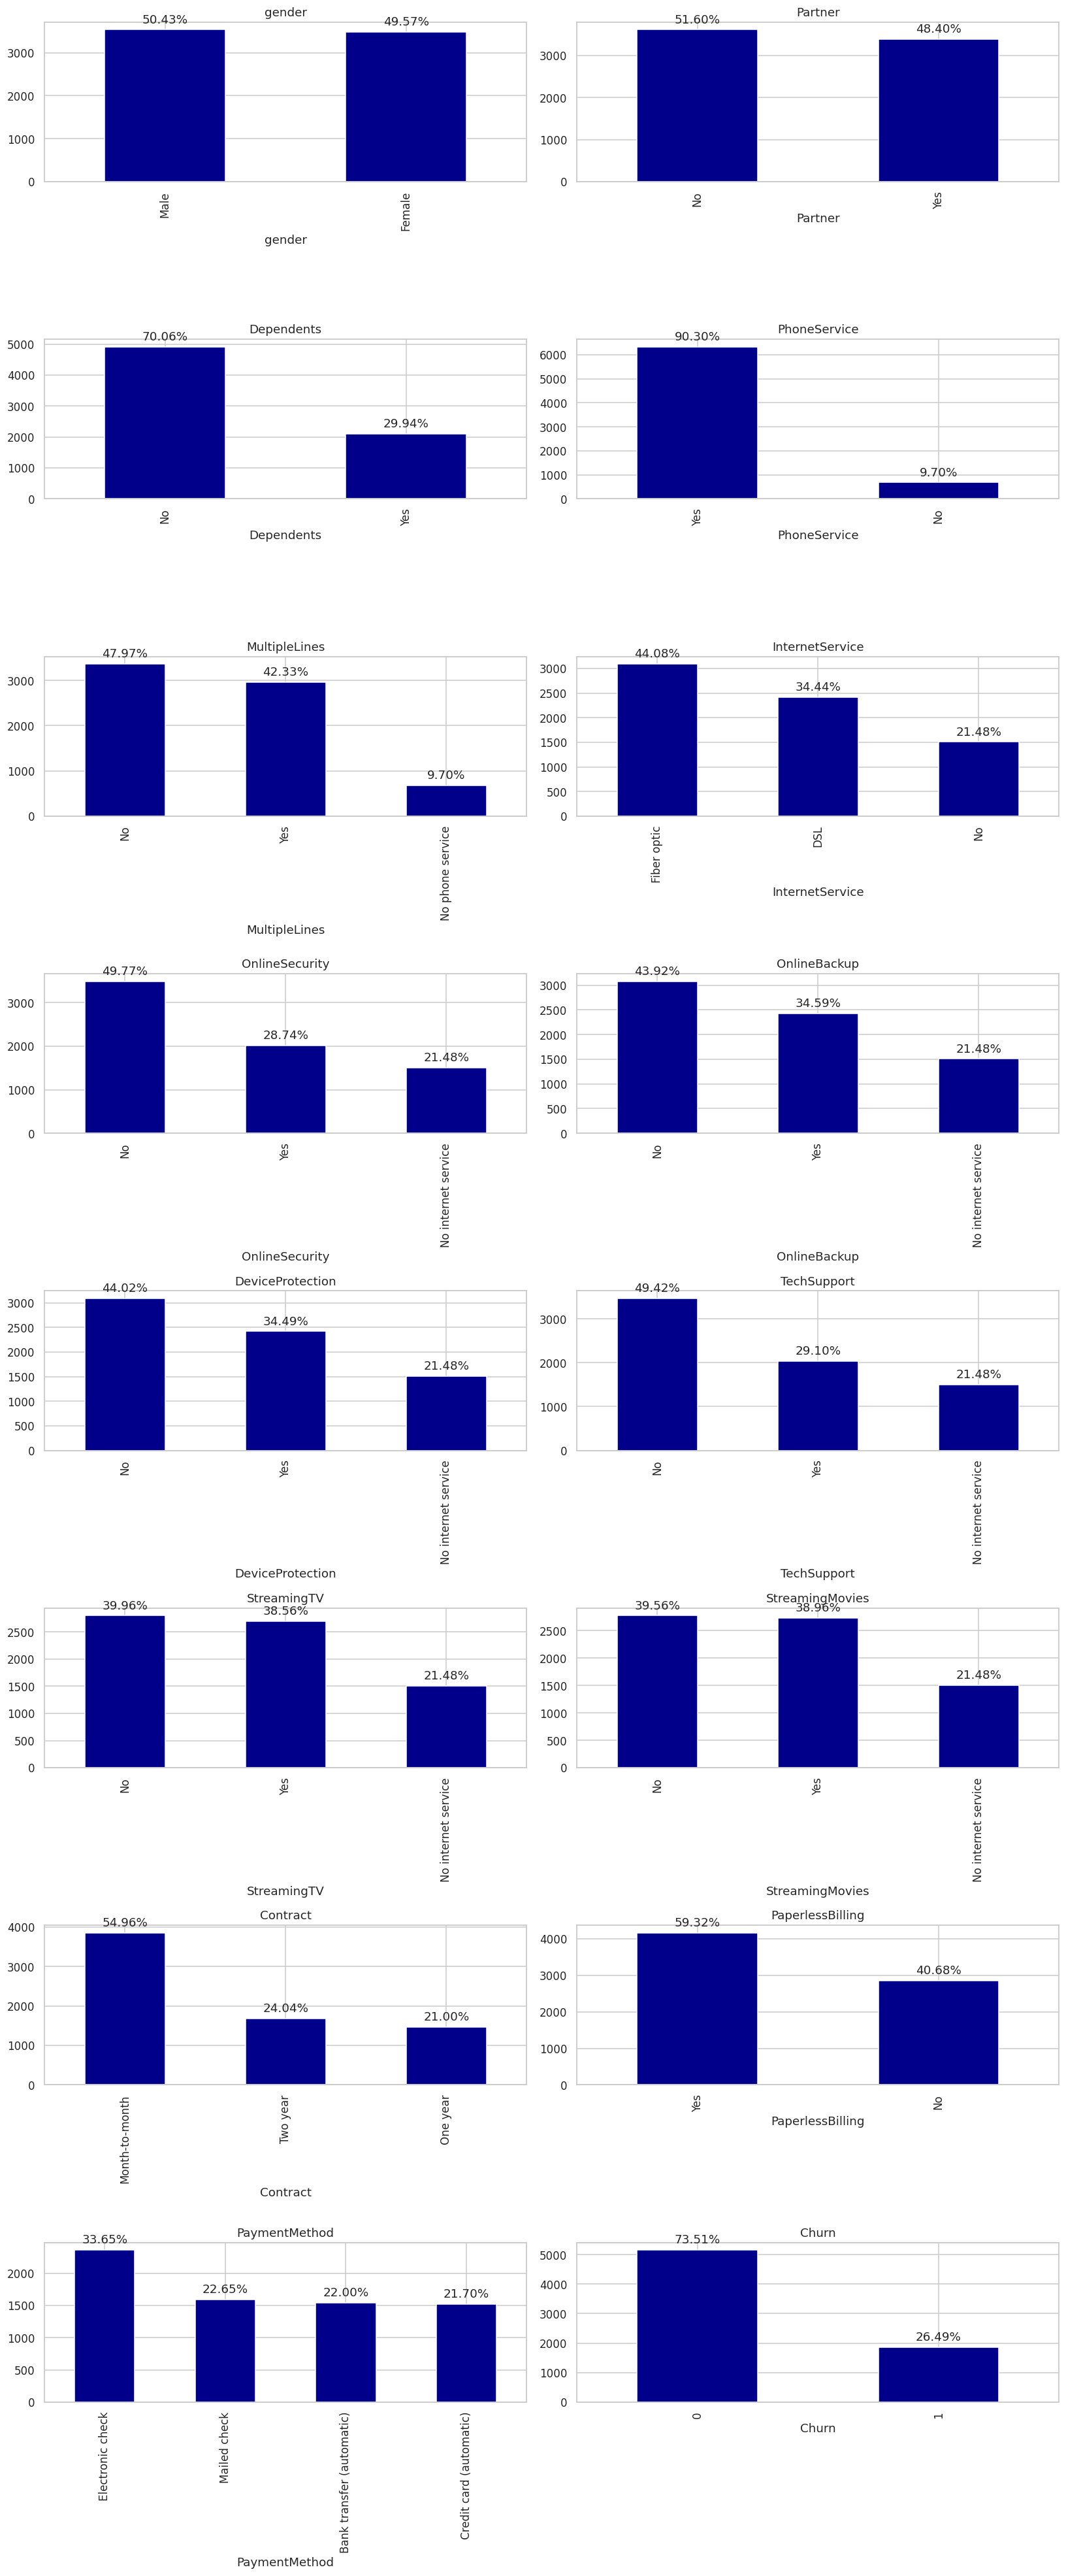

In [ ]:
# Cuadrícula de gráficos de barras con el porcentaje sobre cada barra
columns_per_row = 2
num_rows = math.ceil(len(columnsString) / columns_per_row)

fig, axes = plt.subplots(nrows=num_rows, ncols=columns_per_row, figsize=(15, 4.5 * num_rows))
axes = axes.flatten()
color = "darkblue"

for i, (ax, x) in enumerate(zip(axes, columnsString)):
    counts = df2.fillna("--NULL")[x].value_counts()
    counts.plot(kind="bar", ax=ax, title=x, color=color)
    for p in ax.patches:
        porcentaje = f"{100 * p.get_height() / len(df2):.2f}%"
        ax.annotate(porcentaje,
                    (p.get_x() + p.get_width() / 2., p.get_height()),
                    ha="center", va="center", xytext=(0, 10), textcoords="offset points")

for j in range(i + 1, len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.show()

## 4. Estadísticos descriptivos y distribuciones

In [ ]:
df2.describe().round(2)

,SeniorCitizen,tenure,MonthlyCharges,TotalCharges,Churn
count,7010.00,7010.00,7010.00,7010.00,7010.00
mean,0.16,32.52,64.89,2290.35,0.26
std,0.37,24.52,30.06,2266.82,0.44
min,0.00,1.00,18.25,18.80,0.00
25%,0.00,9.00,35.75,408.31,0.00
50%,0.00,29.00,70.40,1403.88,0.00
75%,0.00,56.00,89.90,3807.84,1.00
max,1.00,72.00,118.75,8684.80,1.00


In [ ]:
df2.describe(include="all").round(2)

,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
count,7010,7010.00,7010,7010,7010.00,7010,7010,7010,7010,7010,7010,7010,7010,7010,7010,7010,7010,7010.00,7010.00,7010.00
unique,2,NaN,2,2,NaN,2,3,3,3,3,3,3,3,3,3,2,4,NaN,NaN,NaN
top,Male,NaN,No,No,NaN,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,NaN,NaN,NaN
freq,3535,NaN,3617,4911,NaN,6330,3363,3090,3489,3079,3086,3464,2801,2773,3853,4158,2359,NaN,NaN,NaN
mean,NaN,0.16,NaN,NaN,32.52,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,64.89,2290.35,0.26
std,NaN,0.37,NaN,NaN,24.52,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,30.06,2266.82,0.44
min,NaN,0.00,NaN,NaN,1.00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,18.25,18.80,0.00
25%,NaN,0.00,NaN,NaN,9.00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,35.75,408.31,0.00
50%,NaN,0.00,NaN,NaN,29.00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,70.40,1403.88,0.00
75%,NaN,0.00,NaN,NaN,56.00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,89.90,3807.84,1.00


* 16% de los clientes son personas senior
* En promedio los clientes permanecen en la compañía 32 meses
* El 50% de los clientes ha estado con la compañía a lo mucho 29 meses
* El cargo promedio mensual es de 64; el cargo máximo es de 118
* En promedio los cargos totales de los clientes han sido 2 290
* 26% de ratio de churn
* No se ven indicios de valores atípicos extremos en `tenure` ni en `MonthlyCharges`

### 4.1 Histogramas

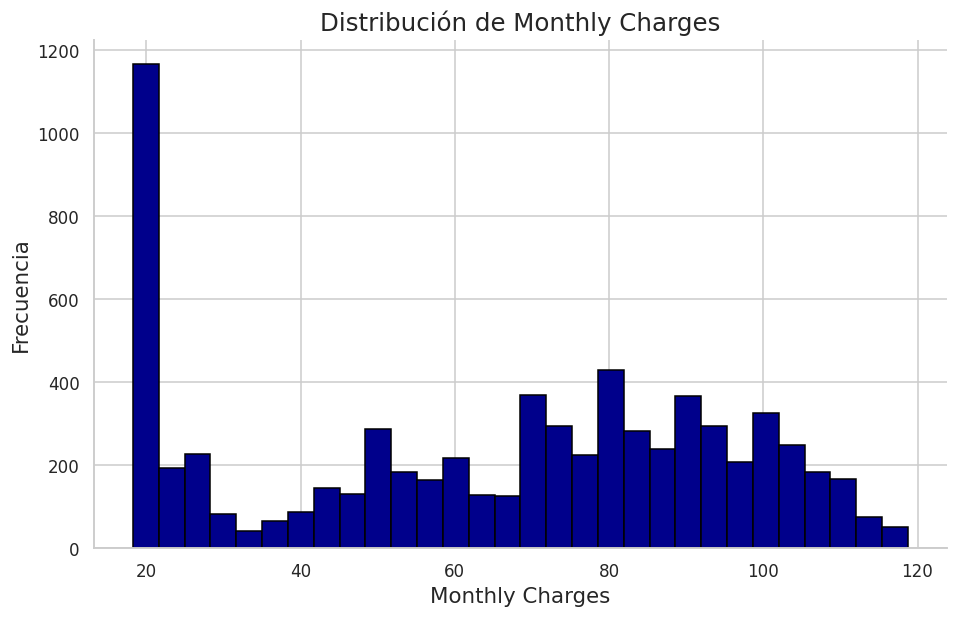

In [ ]:
plt.figure(figsize=(10, 6))
plt.hist(df2["MonthlyCharges"], bins=30, color="darkblue", edgecolor="black")
plt.title("Distribución de Monthly Charges", fontsize=16)
plt.xlabel("Monthly Charges", fontsize=14)
plt.ylabel("Frecuencia", fontsize=14)
plt.gca().spines["top"].set_visible(False)
plt.gca().spines["right"].set_visible(False)
plt.show()

In [ ]:
df2["MonthlyCharges"].mode()

,MonthlyCharges
0,20.05


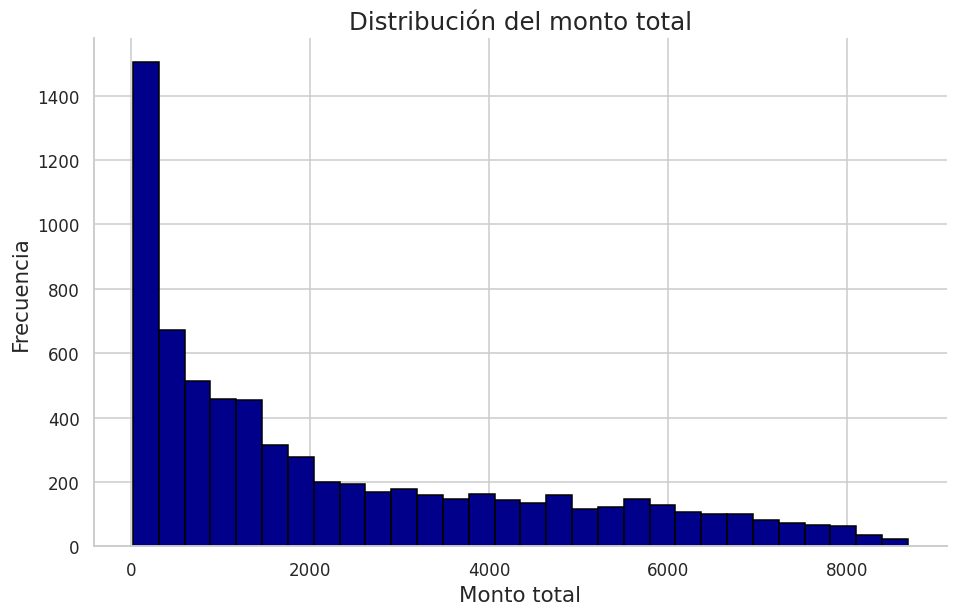

In [ ]:
plt.figure(figsize=(10, 6))
plt.hist(df2["TotalCharges"], bins=30, color="darkblue", edgecolor="black")
plt.title("Distribución del monto total", fontsize=16)
plt.xlabel("Monto total", fontsize=14)
plt.ylabel("Frecuencia", fontsize=14)
plt.gca().spines["top"].set_visible(False)
plt.gca().spines["right"].set_visible(False)
plt.show()

In [ ]:
df2["TotalCharges"].describe()

,TotalCharges
count,7010.000000
mean,2290.353388
std,2266.820832
min,18.800000
25%,408.312500
50%,1403.875000
75%,3807.837500
max,8684.800000


### 4.2 Boxplots — detección de valores atípicos

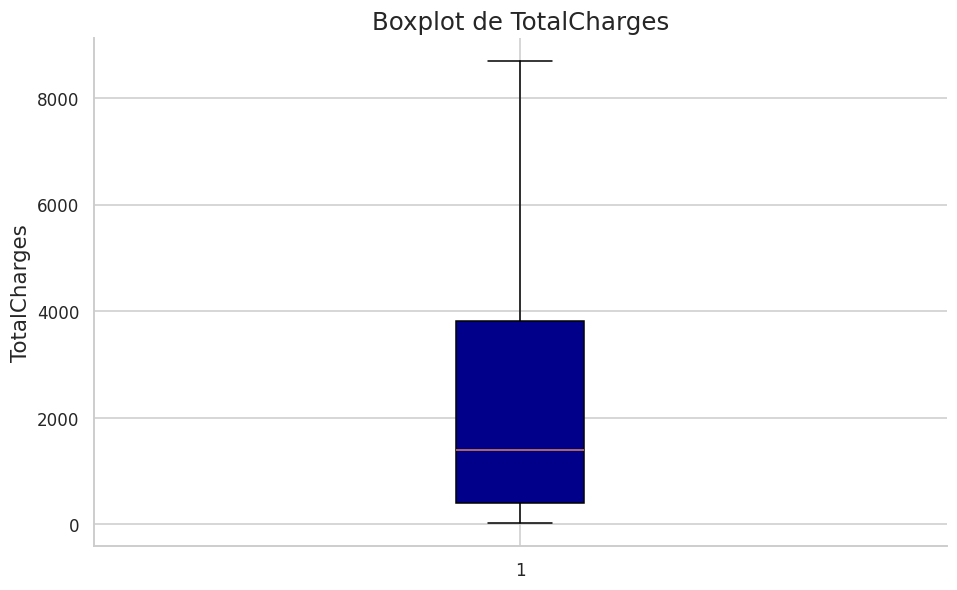

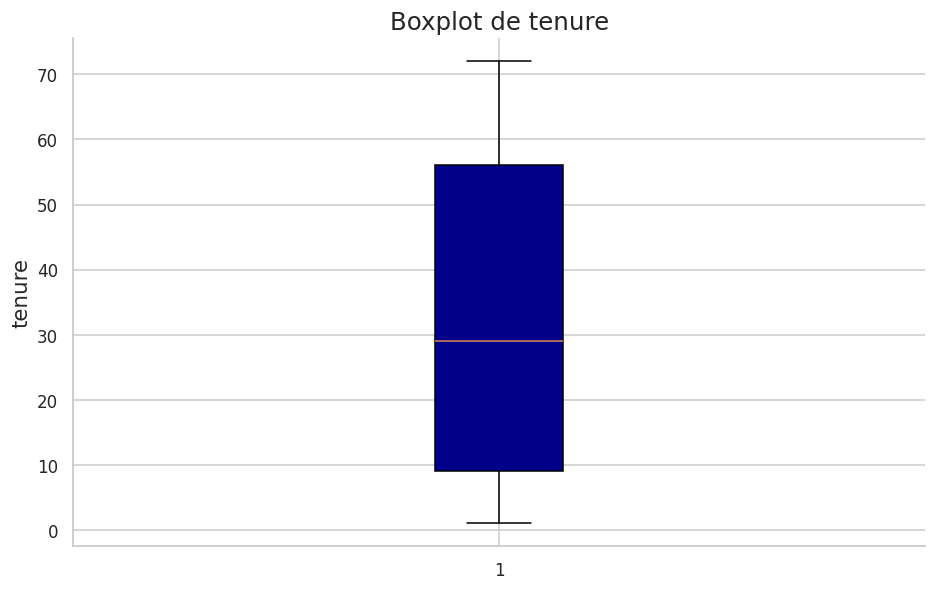

In [ ]:
for col in ["TotalCharges", "tenure"]:
    plt.figure(figsize=(10, 6))
    plt.boxplot(df2[col], vert=True, patch_artist=True, boxprops=dict(facecolor="darkblue"))
    plt.title(f"Boxplot de {col}", fontsize=16)
    plt.ylabel(col, fontsize=14)
    plt.gca().spines["top"].set_visible(False)
    plt.gca().spines["right"].set_visible(False)
    plt.show()

## 5. Análisis bivariado

### 5.1 Variables numéricas según churn

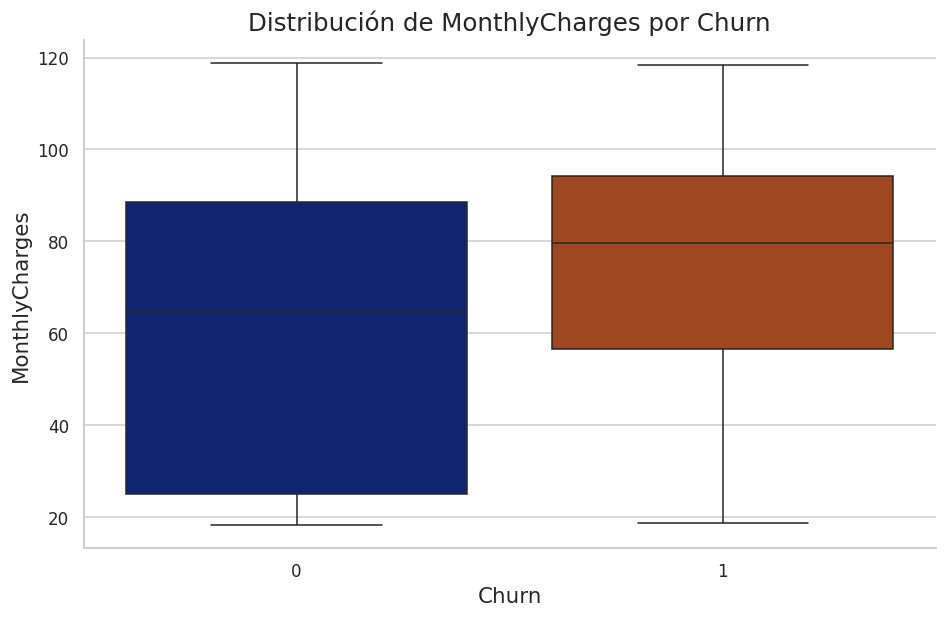

In [ ]:
plt.figure(figsize=(10, 6))
sns.boxplot(x=df2.Churn, y=df2.MonthlyCharges, hue=df2.Churn, palette="dark", linewidth=1, legend=False)
plt.title("Distribución de MonthlyCharges por Churn", fontsize=16)
plt.xlabel("Churn", fontsize=14)
plt.ylabel("MonthlyCharges", fontsize=14)
sns.despine(top=True, right=True)
plt.show()

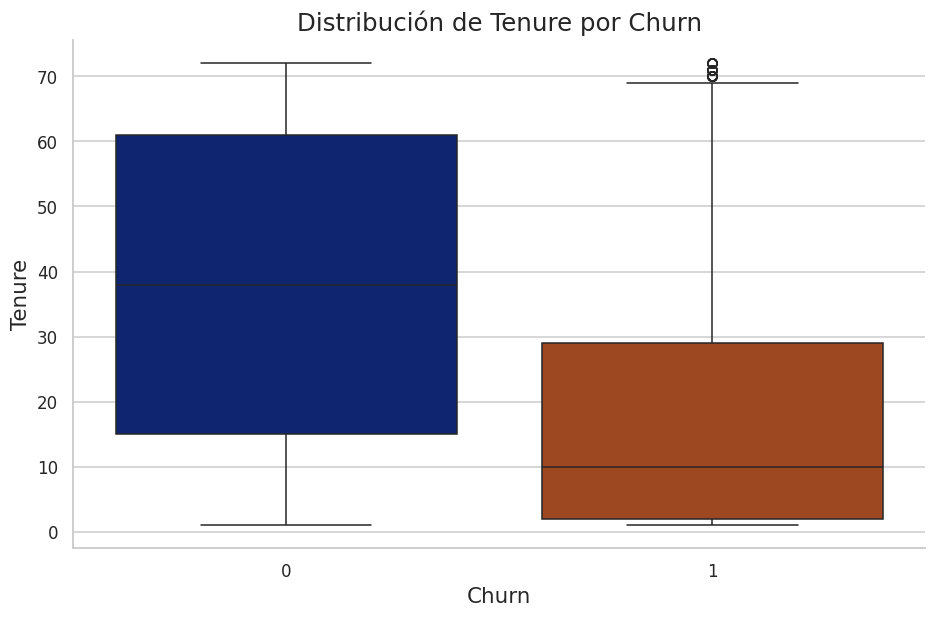

In [ ]:
plt.figure(figsize=(10, 6))
sns.boxplot(x=df2.Churn, y=df2.tenure, hue=df2.Churn, palette="dark", linewidth=1, legend=False)
plt.title("Distribución de Tenure por Churn", fontsize=16)
plt.xlabel("Churn", fontsize=14)
plt.ylabel("Tenure", fontsize=14)
sns.despine(top=True, right=True)
plt.show()

Los clientes que han fugado tienen menos meses en la compañía.

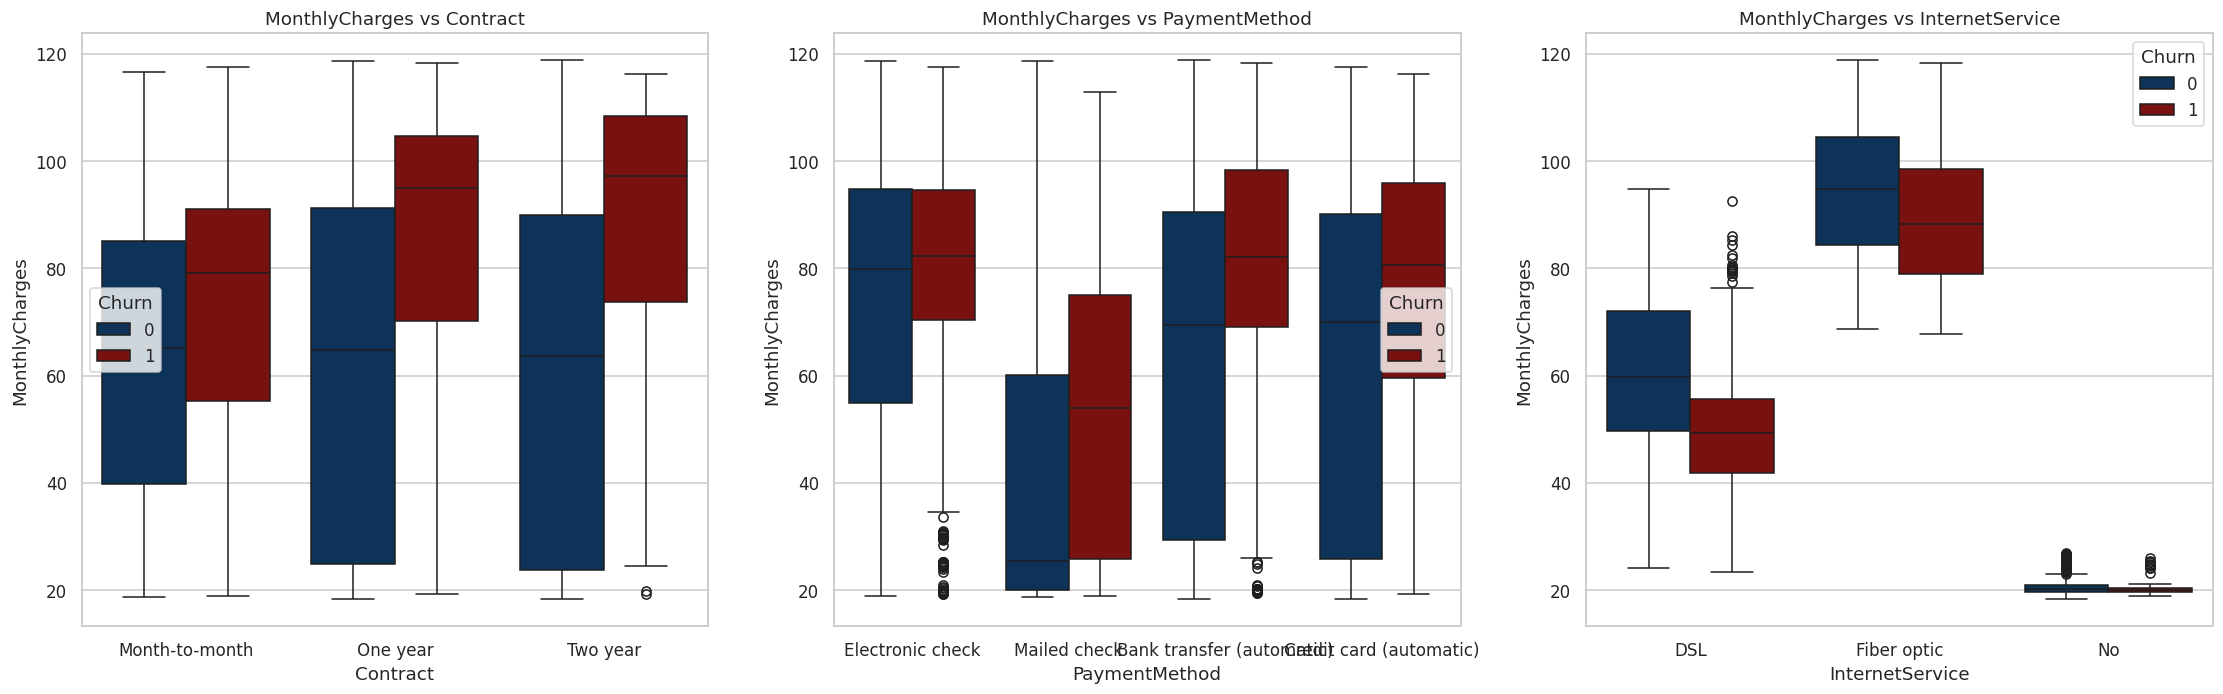

In [ ]:
l3 = ["Contract", "PaymentMethod", "InternetService"]
colors = ["#003366", "#8B0000"]   # azul oscuro y rojo oscuro

fig, axes = plt.subplots(nrows=1, ncols=3, figsize=(25, 7))
for i in range(len(l3)):
    plt.subplot(1, 3, i + 1)
    sns.boxplot(x=l3[i], y="MonthlyCharges", data=df2, hue="Churn", palette=colors)
    plt.title("MonthlyCharges vs " + l3[i])
plt.show()

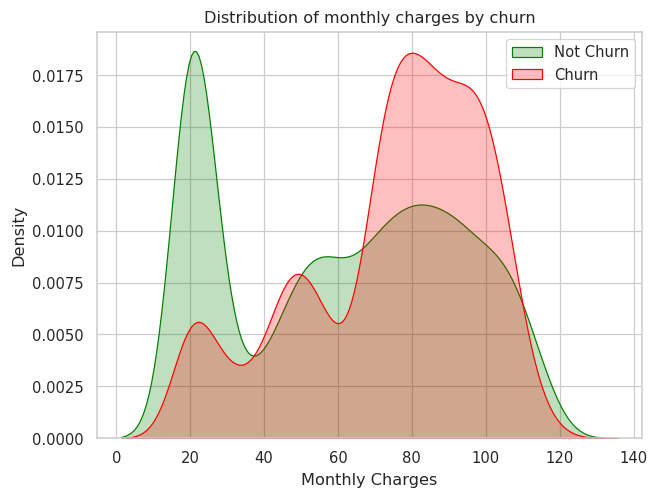

In [ ]:
sns.set_context("paper", font_scale=1.1)
ax = sns.kdeplot(df2.MonthlyCharges[df2["Churn"] == 0], color="green", fill=True)
ax = sns.kdeplot(df2.MonthlyCharges[df2["Churn"] == 1], ax=ax, color="red", fill=True)
ax.legend(["Not Churn", "Churn"], loc="upper right")
ax.set_ylabel("Density")
ax.set_xlabel("Monthly Charges")
ax.set_title("Distribution of monthly charges by churn")
plt.show()

### 5.2 Churn por variable categórica

In [ ]:
def churn_apilado(variable, data=df2):
    """Barras apiladas con el % de churn dentro de cada categoría."""
    tabla = data.groupby(variable)["Churn"].value_counts().unstack()
    tabla_perc = tabla.div(tabla.sum(1), axis=0) * 100

    ax = tabla_perc.plot(kind="bar", stacked=True, color=["#7f7f7f", "#8B0000"], figsize=(10, 6))
    plt.title(f"Churn by {variable}")
    plt.ylabel("% Customers")
    plt.xlabel(variable)
    plt.legend(title="Churn")
    for p in ax.patches:
        width, height = p.get_width(), p.get_height()
        x, y = p.get_xy()
        ax.annotate(f"{height:.0f}%", (x + width / 2, y + height / 2),
                    ha="center", va="center", color="white", fontsize=12, weight="bold")
    plt.show()
    return tabla_perc.round(1)

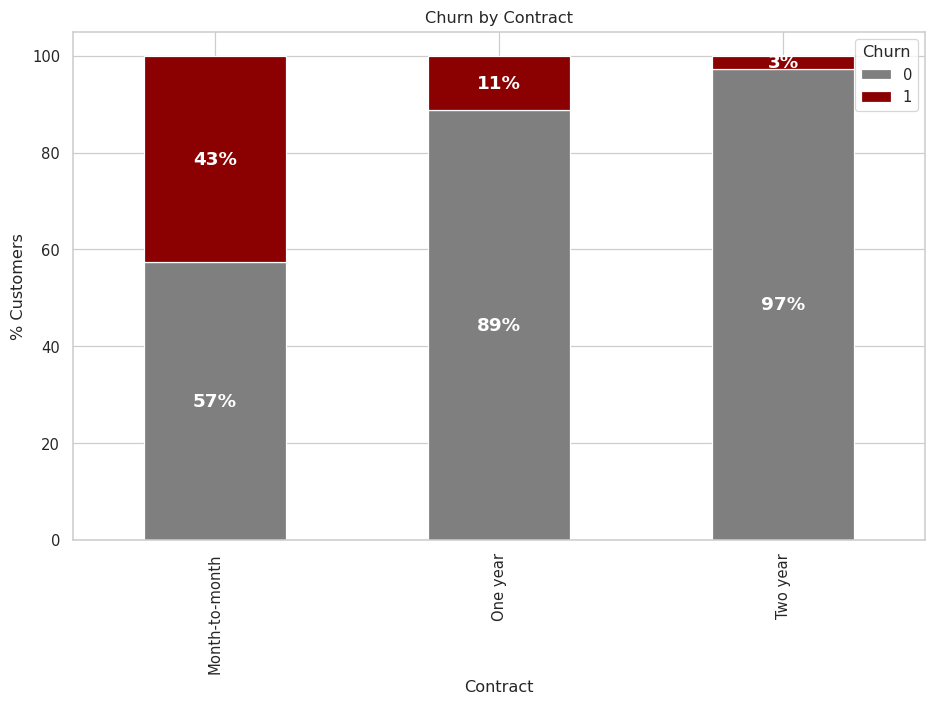

Churn,0,1
Contract,,
Month-to-month,57.4,42.6
One year,88.7,11.3
Two year,97.2,2.8


In [ ]:
churn_apilado("Contract")

El 43% de los clientes con contrato mes a mes ha fugado, frente a solo el 3% de los que tienen contrato a 2 años.

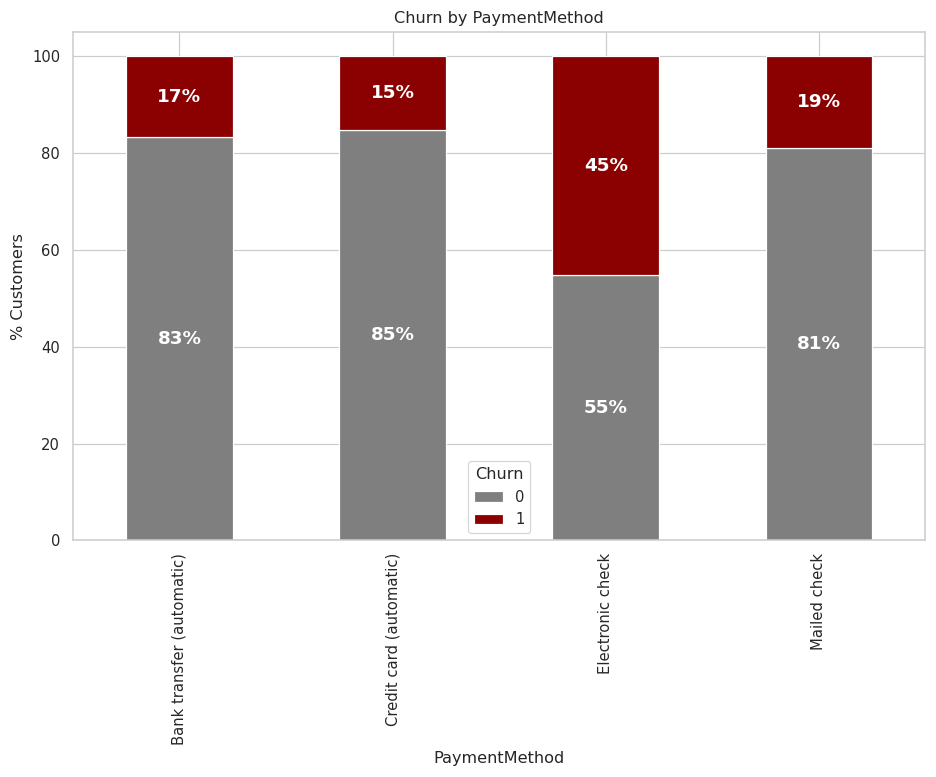

Churn,0,1
PaymentMethod,,
Bank transfer (automatic),83.3,16.7
Credit card (automatic),84.7,15.3
Electronic check,54.9,45.1
Mailed check,81.0,19.0


In [ ]:
churn_apilado("PaymentMethod")

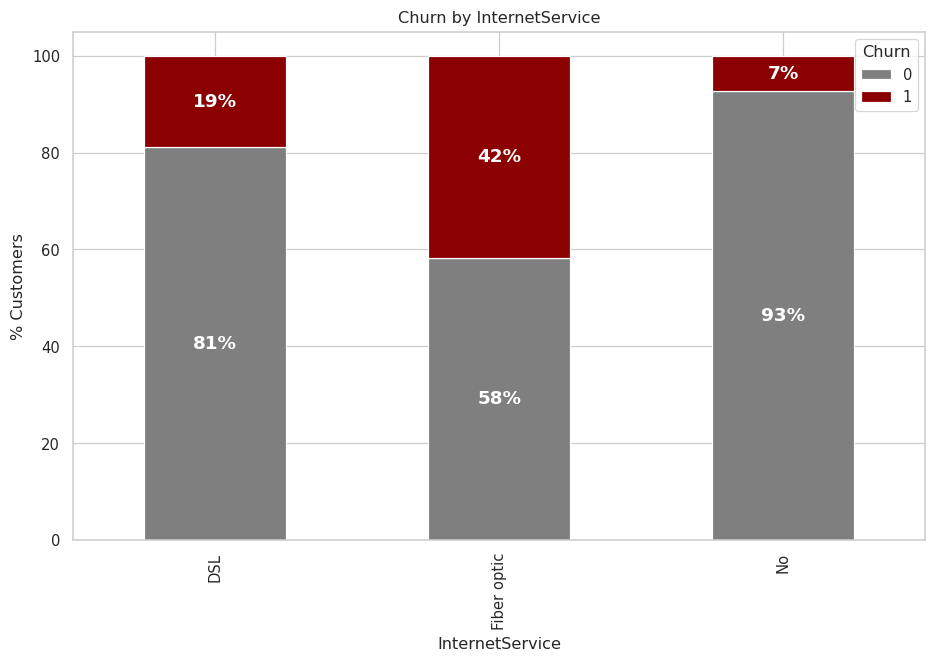

Churn,0,1
InternetService,,
DSL,81.1,18.9
Fiber optic,58.2,41.8
No,92.8,7.2


In [ ]:
churn_apilado("InternetService")

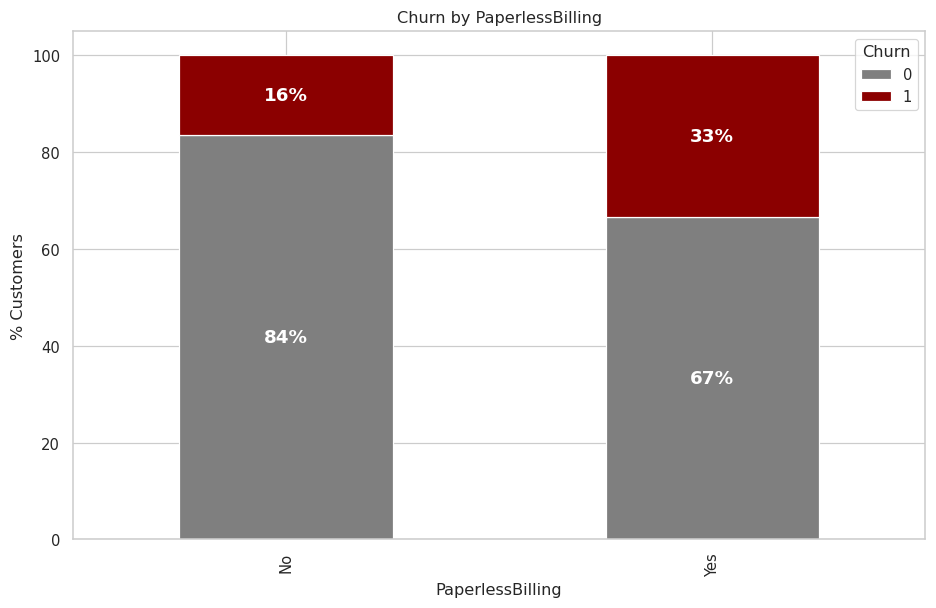

Churn,0,1
PaperlessBilling,,
No,83.7,16.3
Yes,66.5,33.5


In [ ]:
churn_apilado("PaperlessBilling")

### 5.3 Tasa de fuga por categoría vs. tasa global

In [ ]:
tasa_global = df2["Churn"].mean()
print(f"Tasa de fuga global: {tasa_global:.1%}")


def tasa_fuga(variable, data=df2):
    """Clientes, tasa de fuga e índice de cada categoría respecto de la tasa global."""
    t = data.groupby(variable)["Churn"].agg(Clientes="size", Fugados="sum", Tasa="mean")
    t["Tasa"] = (100 * t["Tasa"]).round(1)
    t["Indice"] = (t["Tasa"] / (100 * data["Churn"].mean())).round(2)
    return t.sort_values("Tasa", ascending=False)


tasa_fuga("Contract")

Tasa de fuga global: 26.5%


,Clientes,Fugados,Tasa,Indice
Contract,,,,
Month-to-month,3853,1643,42.6,1.61
One year,1472,166,11.3,0.43
Two year,1685,48,2.8,0.11


In [ ]:
for x in columnsString[:-1]:      # todas las categóricas menos Churn
    print(tasa_fuga(x)[["Clientes", "Tasa", "Indice"]], "\n")

        Clientes  Tasa  Indice
gender                        
Female      3475  26.9    1.02
Male        3535  26.1    0.99 

         Clientes  Tasa  Indice
Partner                        
No           3617  32.8    1.24
Yes          3393  19.7    0.74 

            Clientes  Tasa  Indice
Dependents                        
No              4911  31.2    1.18
Yes             2099  15.5    0.59 

              Clientes  Tasa  Indice
PhoneService                        
Yes               6330  26.7    1.01
No                 680  25.0    0.94 

                  Clientes  Tasa  Indice
MultipleLines                           
Yes                   2967  28.6    1.08
No phone service       680  25.0    0.94
No                    3363  24.9    0.94 

                 Clientes  Tasa  Indice
InternetService                        
Fiber optic          3090  41.8    1.58
DSL                  2414  18.9    0.71
No                   1506   7.2    0.27 

                     Clientes  Tasa  Indice

### 5.4 Relaciones entre las variables numéricas

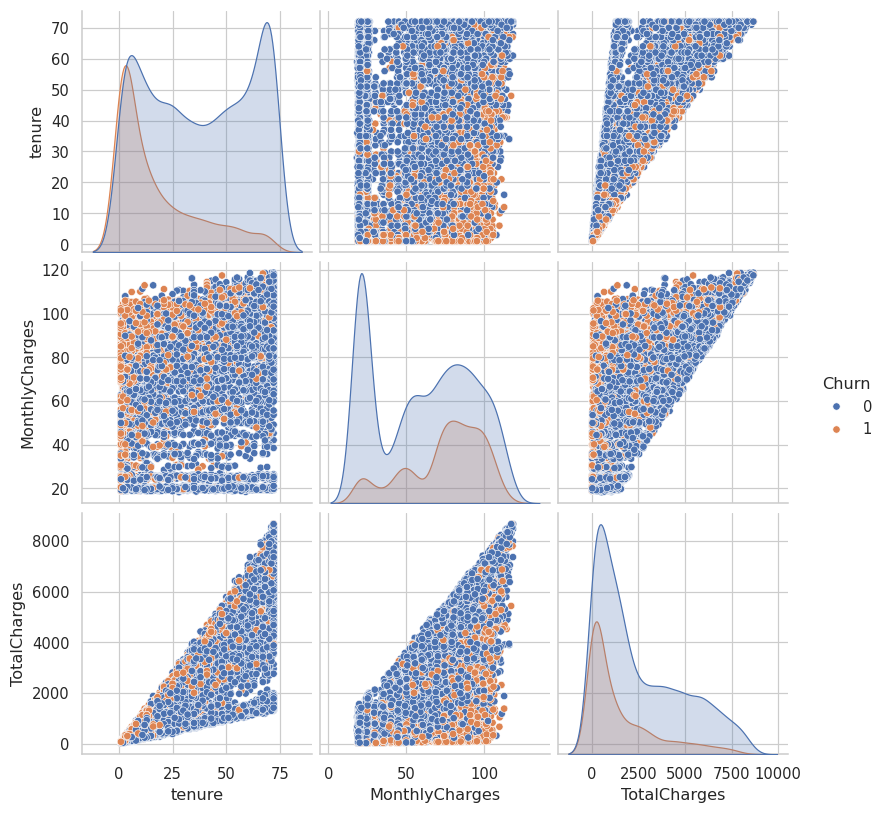

In [ ]:
sns.pairplot(df2[["tenure", "MonthlyCharges", "TotalCharges", "Churn"]], hue="Churn")
plt.show()

## 6. Correlaciones

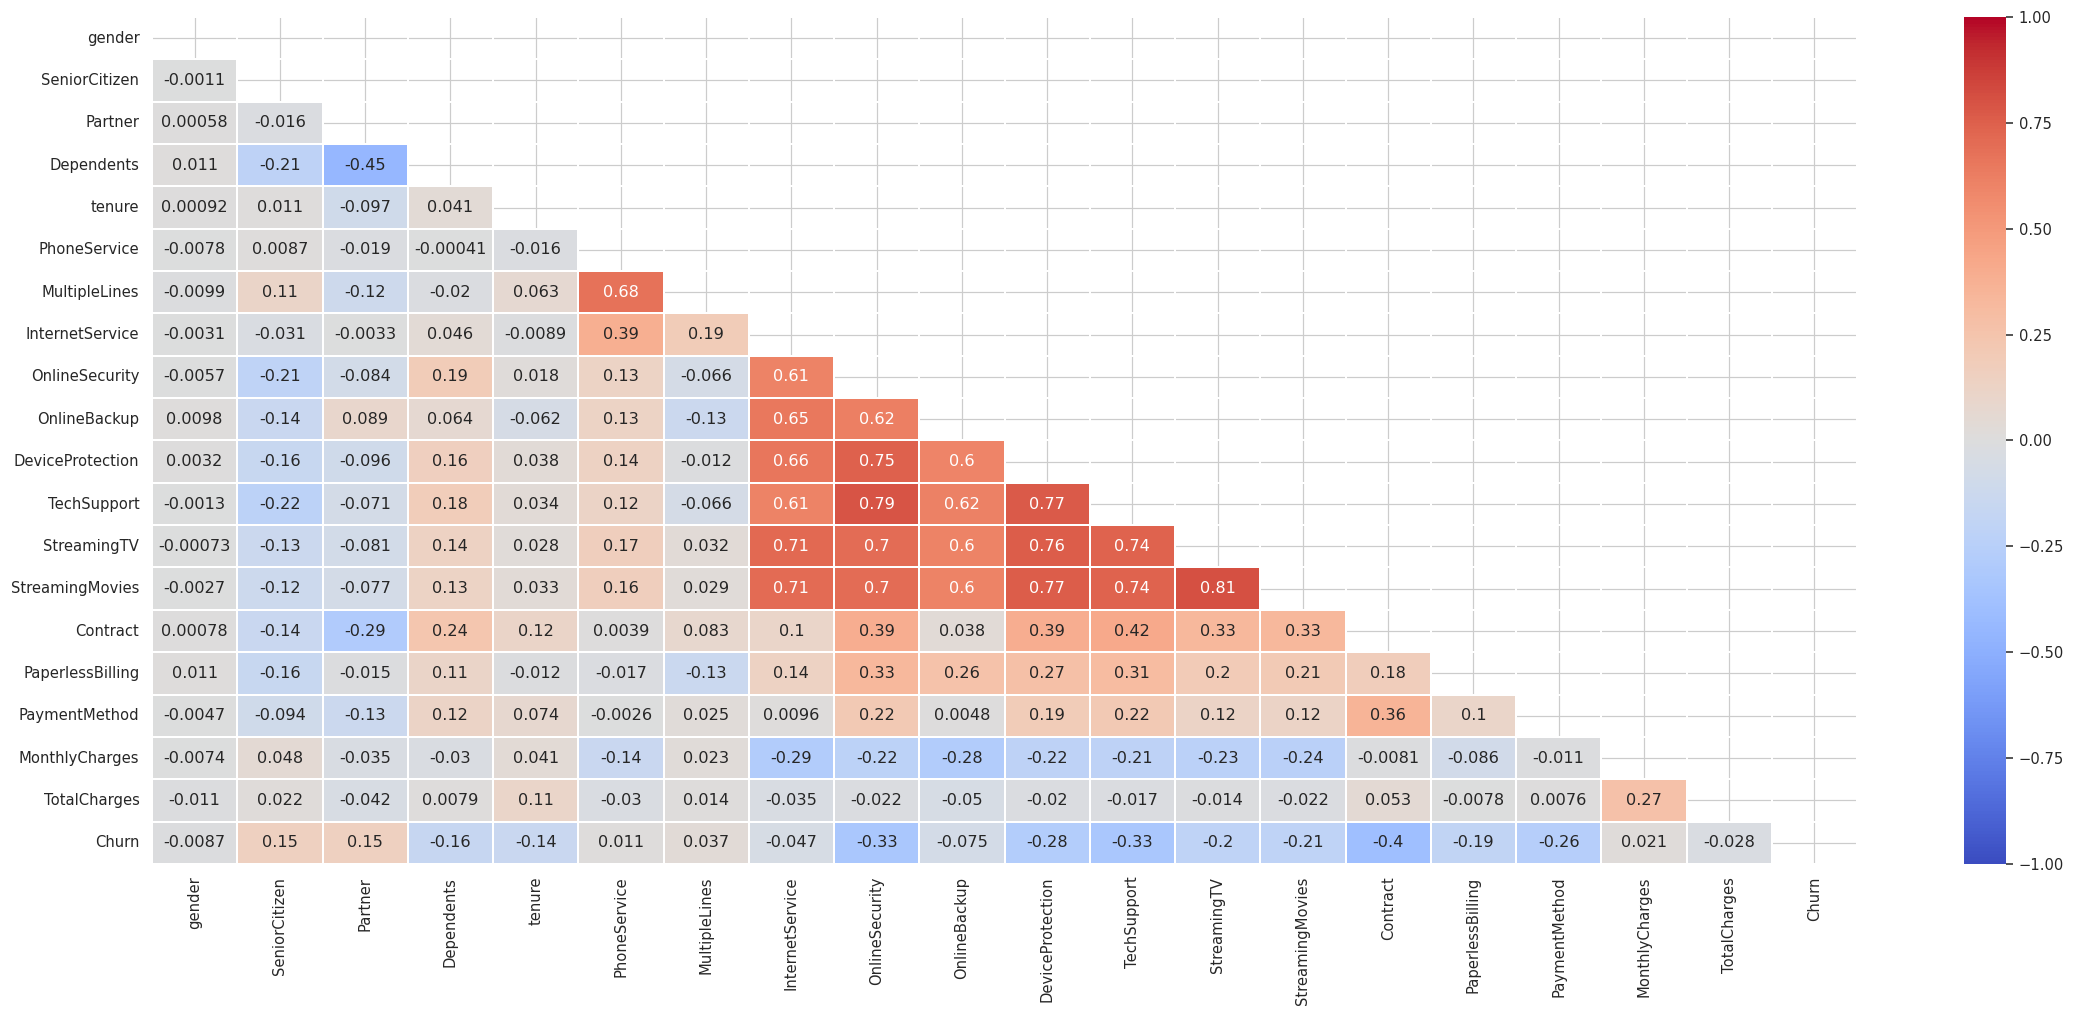

In [ ]:
plt.figure(figsize=(25, 10))

# pd.factorize convierte las categóricas en códigos numéricos antes de correlacionar
corr = df2.apply(lambda x: pd.factorize(x)[0]).corr()

# Máscara triangular superior
mask = np.triu(np.ones_like(corr, dtype=bool))

sns.heatmap(corr, mask=mask, xticklabels=corr.columns, yticklabels=corr.columns,
            annot=True, linewidths=.2, cmap="coolwarm", vmin=-1, vmax=1)
plt.show()

> `factorize` asigna códigos según el orden de aparición de cada categoría, por lo que la correlación entre variables nominales no es interpretable. La alternativa es binarizar (one-hot) y correlacionar contra la variable objetivo.

In [ ]:
# Variables categóricas convertidas en dummies
df_dummies = pd.get_dummies(df2, dtype=int)
df_dummies.head()

,SeniorCitizen,tenure,MonthlyCharges,TotalCharges,Churn,gender_Female,gender_Male,Partner_No,Partner_Yes,Dependents_No,Dependents_Yes,PhoneService_No,PhoneService_Yes,MultipleLines_No,MultipleLines_No phone service,MultipleLines_Yes,InternetService_DSL,InternetService_Fiber optic,InternetService_No,OnlineSecurity_No,OnlineSecurity_No internet service,OnlineSecurity_Yes,OnlineBackup_No,OnlineBackup_No internet service,OnlineBackup_Yes,DeviceProtection_No,DeviceProtection_No internet service,DeviceProtection_Yes,TechSupport_No,TechSupport_No internet service,TechSupport_Yes,StreamingTV_No,StreamingTV_No internet service,StreamingTV_Yes,StreamingMovies_No,StreamingMovies_No internet service,StreamingMovies_Yes,Contract_Month-to-month,Contract_One year,Contract_Two year,PaperlessBilling_No,PaperlessBilling_Yes,PaymentMethod_Bank transfer (automatic),PaymentMethod_Credit card (automatic),PaymentMethod_Electronic check,PaymentMethod_Mailed check
0,0,1,29.85,29.85,0,1,0,0,1,1,0,1,0,0,1,0,1,0,0,1,0,0,0,0,1,1,0,0,1,0,0,1,0,0,1,0,0,1,0,0,0,1,0,0,1,0
1,0,34,56.95,1889.50,0,0,1,1,0,1,0,0,1,1,0,0,1,0,0,0,0,1,1,0,0,0,0,1,1,0,0,1,0,0,1,0,0,0,1,0,1,0,0,0,0,1
2,0,2,53.85,108.15,1,0,1,1,0,1,0,0,1,1,0,0,1,0,0,0,0,1,0,0,1,1,0,0,1,0,0,1,0,0,1,0,0,1,0,0,0,1,0,0,0,1
3,0,45,42.30,1840.75,0,0,1,1,0,1,0,1,0,0,1,0,1,0,0,0,0,1,1,0,0,0,0,1,0,0,1,1,0,0,1,0,0,0,1,0,1,0,1,0,0,0
4,0,2,70.70,151.65,1,1,0,1,0,1,0,0,1,1,0,0,0,1,0,1,0,0,1,0,0,1,0,0,1,0,0,1,0,0,1,0,0,1,0,0,0,1,0,0,1,0


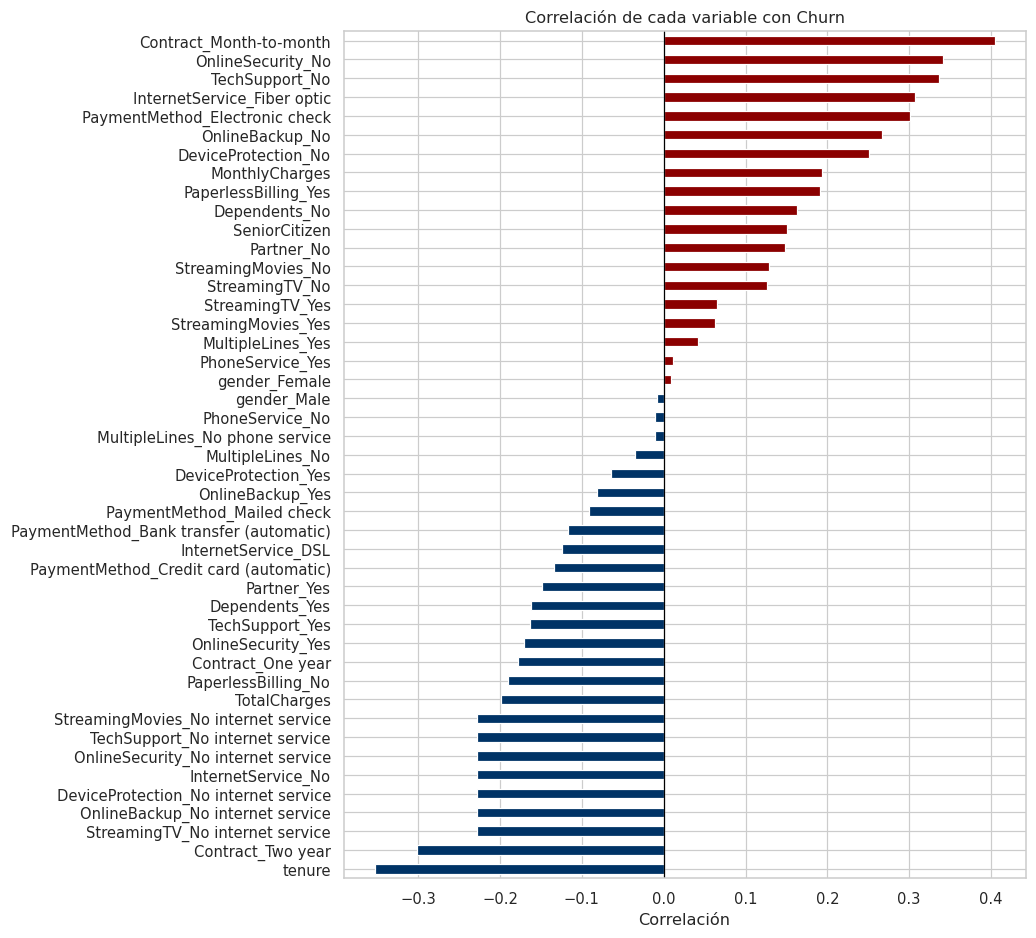

In [ ]:
corr_churn = df_dummies.corr()["Churn"].drop("Churn").sort_values()

plt.figure(figsize=(8, 10))
corr_churn.plot(kind="barh", color=["#003366" if v < 0 else "#8B0000" for v in corr_churn])
plt.axvline(0, color="black", lw=.8)
plt.title("Correlación de cada variable con Churn")
plt.xlabel("Correlación")
plt.show()

## 7. Perfiles agrupados

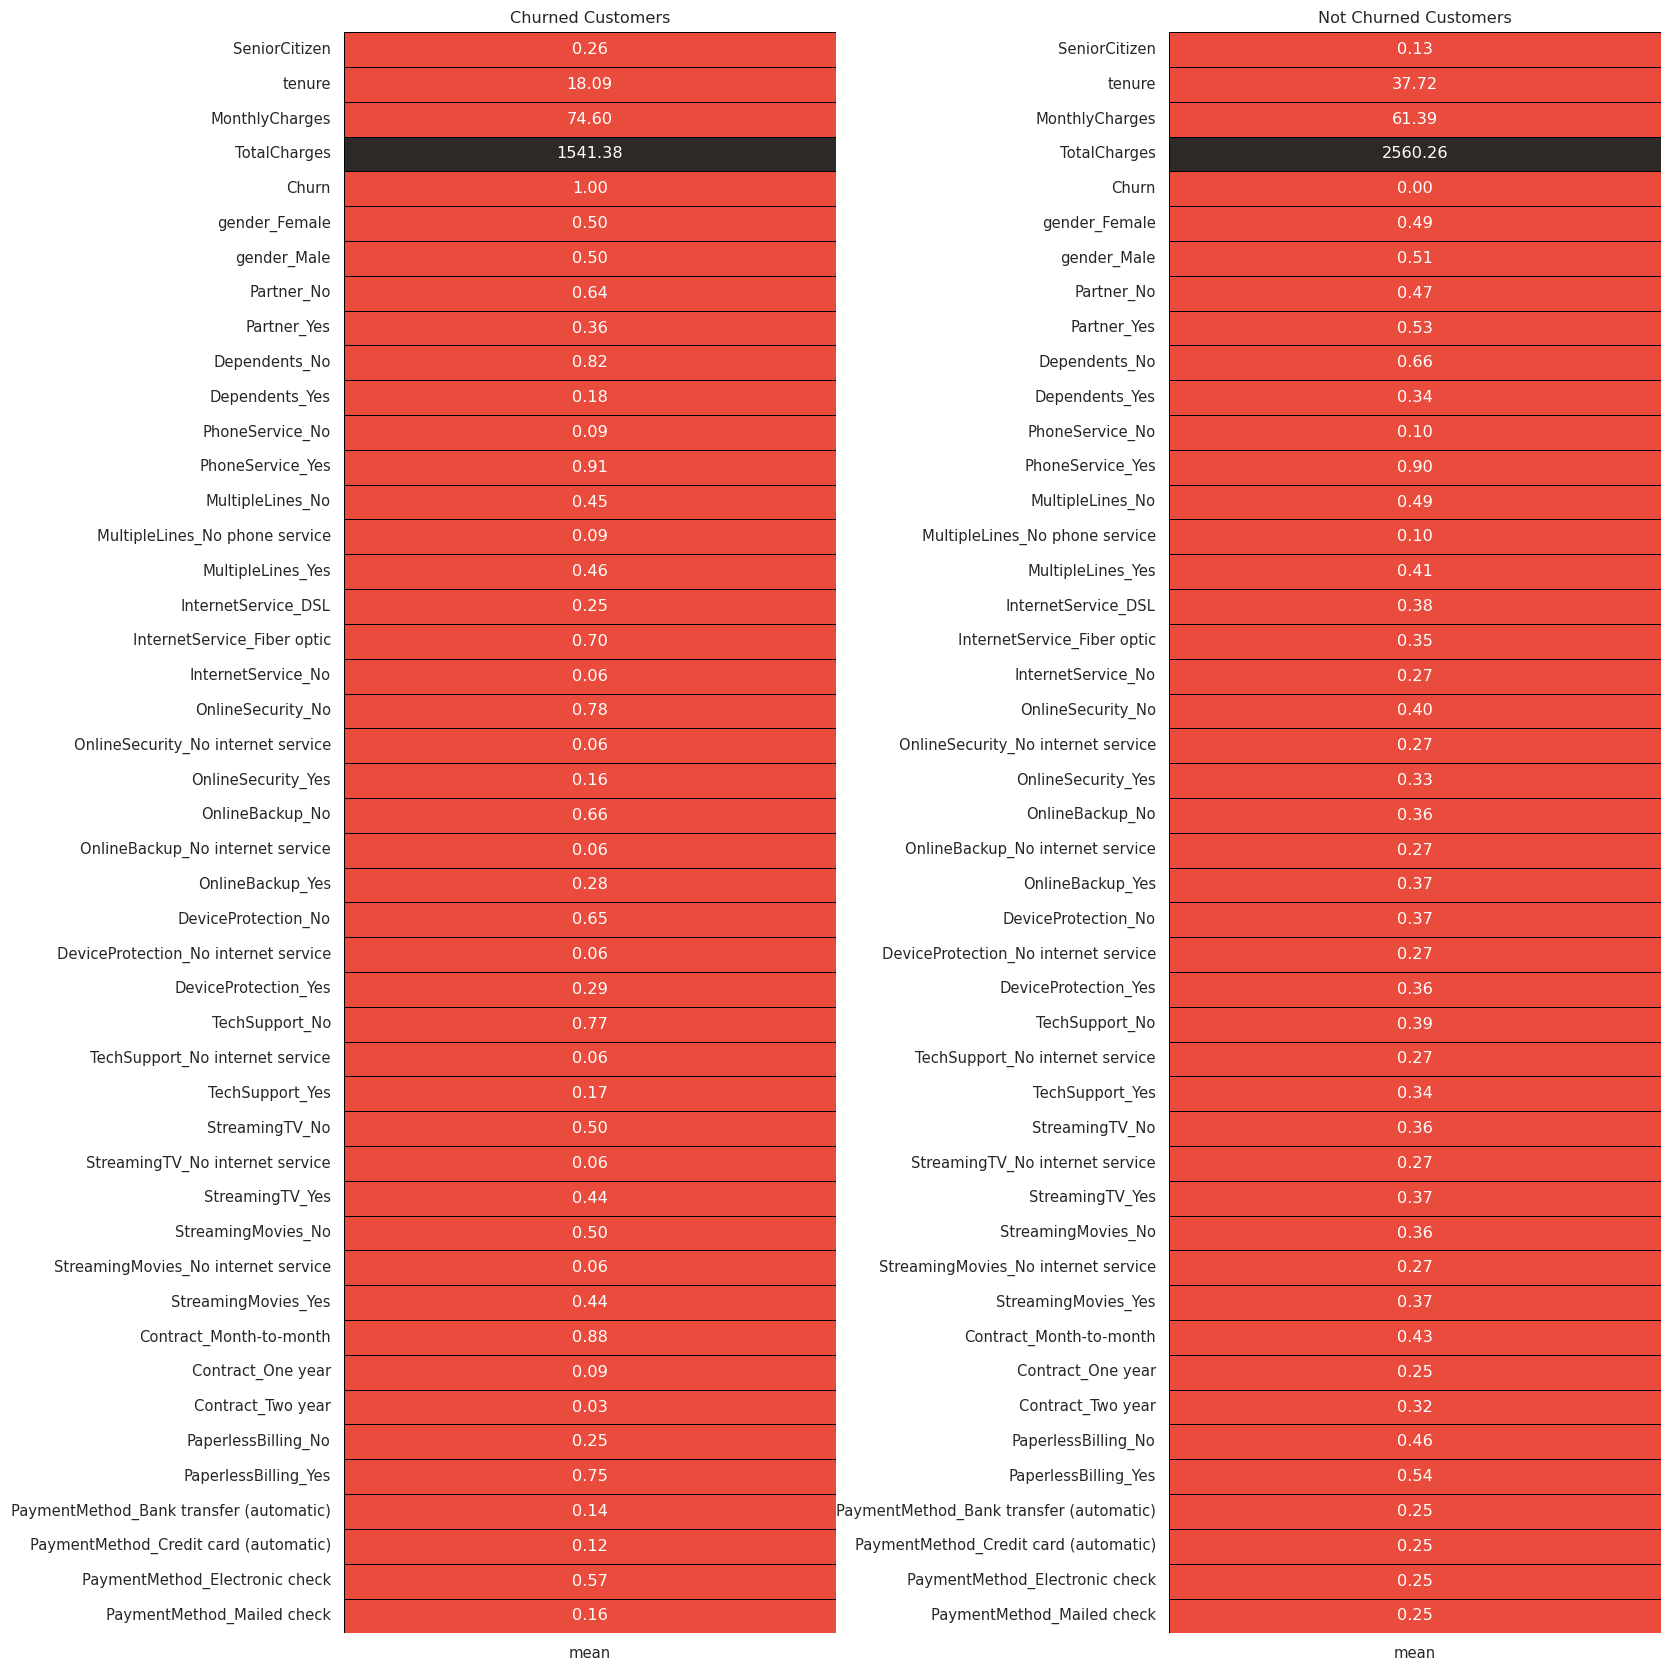

In [ ]:
colors = ["#E94B3C", "#2D2926"]

churn = df_dummies[df_dummies["Churn"] == 1].describe().T
not_churn = df_dummies[df_dummies["Churn"] == 0].describe().T

fig, ax = plt.subplots(nrows=1, ncols=2, figsize=(15, 15))

plt.subplot(1, 2, 1)
sns.heatmap(churn[["mean"]], annot=True, cmap=colors, linewidths=0.4,
            linecolor="black", cbar=False, fmt=".2f")
plt.title("Churned Customers")

plt.subplot(1, 2, 2)
sns.heatmap(not_churn[["mean"]], annot=True, cmap=colors, linewidths=0.4,
            linecolor="black", cbar=False, fmt=".2f")
plt.title("Not Churned Customers")

fig.tight_layout(pad=0)
plt.show()

In [ ]:
# Comparación de medias entre ambos grupos
churn_summary = df_dummies.groupby("Churn").mean().transpose()
churn_summary.round(2)

Churn,0,1
SeniorCitizen,0.13,0.26
tenure,37.72,18.09
MonthlyCharges,61.39,74.60
TotalCharges,2560.26,1541.38
gender_Female,0.49,0.50
gender_Male,0.51,0.50
Partner_No,0.47,0.64
Partner_Yes,0.53,0.36
Dependents_No,0.66,0.82
Dependents_Yes,0.34,0.18


In [ ]:
grouped_stats = df2.groupby(["PaymentMethod", "Churn"]).agg(
    AvgMonthlyCharges=("MonthlyCharges", "mean"),
    Avg_tenure=("tenure", "mean"),
    MedianTotalCharges=("TotalCharges", "median"),
    AvgTotalCharges=("TotalCharges", "mean")
).reset_index()
grouped_stats.round(2)

,PaymentMethod,Churn,AvgMonthlyCharges,Avg_tenure,MedianTotalCharges,AvgTotalCharges
0,Bank transfer (automatic),0,65.06,47.21,2673.80,3241.95
1,Bank transfer (automatic),1,77.88,26.29,1306.70,2269.81
2,Credit card (automatic),0,64.57,46.14,2633.30,3201.19
3,Credit card (automatic),1,77.36,27.52,1478.40,2350.26
4,Electronic check,0,74.23,32.14,1883.85,2609.99
5,Electronic check,1,78.77,16.85,713.10,1471.53
6,Mailed check,0,41.61,25.43,602.25,1187.18
7,Mailed check,1,54.99,8.20,120.38,543.98


In [ ]:
grouped_stats = df2.groupby(["Churn"]).agg(
    AvgMonthlyCharges=("MonthlyCharges", "mean"),
    Avg_tenure=("tenure", "mean"),
    MedianTotalCharges=("TotalCharges", "median"),
    SumaMonthlyCharges=("MonthlyCharges", "sum"),
    AvgTotalCharges=("TotalCharges", "mean")
).reset_index()
grouped_stats.round(2)

,Churn,AvgMonthlyCharges,Avg_tenure,MedianTotalCharges,SumaMonthlyCharges,AvgTotalCharges
0,0,61.39,37.72,1688.9,316329.35,2560.26
1,1,74.60,18.09,713.1,138540.20,1541.38


In [ ]:
df2.groupby(["PaymentMethod", "Churn"]).describe()

SeniorCitizen                                \
                                        count      mean       std  min  25%   
PaymentMethod             Churn                                               
Bank transfer (automatic) 0            1284.0  0.140187  0.347316  0.0  0.0   
                          1             258.0  0.205426  0.404798  0.0  0.0   
Credit card (automatic)   0            1289.0  0.123351  0.328968  0.0  0.0   
                          1             232.0  0.267241  0.443476  0.0  0.0   
Electronic check          0            1294.0  0.214065  0.410331  0.0  0.0   
                          1            1065.0  0.296714  0.457024  0.0  0.0   
Mailed check              0            1286.0  0.038880  0.193385  0.0  0.0   
                          1             302.0  0.145695  0.353386  0.0  0.0   

                                                tenure                        \
                                 50%  75%  max   count       mean        std   
PaymentMethod             Churn                                                
Bank transfer (automatic) 0      0.0  0.0  1.0  1284.0  47.214174  21.799878   
                          1      0.0  0.0  1.0   258.0  26.290698  21.855486   
Credit card (automatic)   0      0.0  0.0  1.0  1289.0  46.137316  22.388695   
                          1      0.0  1.0  1.0   232.0  27.521552  22.109516   
Electronic check          0      0.0  0.0  1.0  1294.0  32.136012  22.968893   
                          1      0.0  1.0  1.0  1065.0  16.852582  18.449429   
Mailed check              0      0.0  0.0  1.0  1286.0  25.426905  21.603153   
                          1      0.0  0.0  1.0   302.0   8.195364  11.821411   

                                                              MonthlyCharges  \
                                 min    25%   50%   75%   max          count   
PaymentMethod             Churn                                                
Bank transfer (automatic) 0      1.0  29.75  52.0  68.0  72.0         1284.0   
                          1      1.0   7.00  21.0  46.0  72.0          258.0   
Credit card (automatic)   0      1.0  27.00  51.0  67.0  72.0         1289.0   
                          1      1.0   7.75  22.5  45.0  72.0          232.0   
Electronic check          0      1.0  11.00  30.0  53.0  72.0         1294.0   
                          1      1.0   2.00   9.0  26.0  72.0         1065.0   
Mailed check              0      1.0   6.00  20.0  41.0  72.0         1286.0   
                          1      1.0   1.00   3.0  10.0  61.0          302.0   

                                                                               \
                                      mean        std    min      25%     50%   
PaymentMethod             Churn                                                 
Bank transfer (automatic) 0      65.061604  31.017119  18.40  29.3500  69.500   
                          1      77.875581  25.774626  19.40  69.1250  82.075   
Credit card (automatic)   0      64.568813  31.322307  18.25  25.8000  69.950   
                          1      77.356034  23.673652  19.30  59.4625  80.575   
Electronic check          0      74.232032  26.094541  18.85  54.8625  79.800   
                          1      78.774930  21.108528  19.25  70.3000  82.300   
Mailed check              0      41.605599  25.695783  18.70  20.0500  25.450   
                          1      54.988079  26.376810  18.85  25.7250  53.875   

                                                 TotalCharges               \
                                     75%     max        count         mean   
PaymentMethod             Churn                                              
Bank transfer (automatic) 0      90.4750  118.75       1284.0  3241.953388   
                          1      98.2625  118.35        258.0  2269.812984   
Credit card (automatic)   0      90.2000  117.50       1289.0  3201.189721   
                          1      95.9625

## 8. Insights

### 8.1 Ingreso mensual en riesgo

In [ ]:
ingreso_total = df2["MonthlyCharges"].sum()
ingreso_riesgo = df2.loc[df2["Churn"] == 1, "MonthlyCharges"].sum()

print(f"Ingreso mensual facturado:  US$ {ingreso_total:,.0f}")
print(f"Ingreso mensual en riesgo:  US$ {ingreso_riesgo:,.0f}  ({ingreso_riesgo / ingreso_total:.1%})")
print(f"Proyección anualizada:      US$ {ingreso_riesgo * 12:,.0f}")

Ingreso mensual facturado:  US$ 454,870
Ingreso mensual en riesgo:  US$ 138,540  (30.5%)
Proyección anualizada:      US$ 1,662,482


### 8.2 Hallazgos y recomendación

Máximo 5 hallazgos, cada uno respaldado por una tabla o gráfico del cuaderno.

1.
2.
3.
4.
5.

**Recomendación para el área comercial:**